In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [5]:
# Charger le dataset
df = pd.read_csv("/content/insurance_fraud_text.csv")

# Afficher les premières lignes
print("Premières lignes du dataset :")
display(df.head())

# Afficher les dimensions
print("\nDimensions du dataset :", df.shape)

# Afficher les noms des colonnes
print("\nColonnes :", df.columns.tolist())

Premières lignes du dataset :


,claim_text_enriched,fraud_label
0,"The customer, aged 74, another policyholder wo...",1
1,"The customer, aged 74, a male policyholder wor...",0
2,"The customer, aged 28, another policyholder wo...",0
3,"The customer, aged 37, a male policyholder wor...",0
4,"The customer, aged 31, another policyholder wo...",0



Dimensions du dataset : (30000, 2)

Colonnes : ['claim_text_enriched', 'fraud_label']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   claim_text_enriched  30000 non-null  object
 1   fraud_label          30000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 468.9+ KB


In [7]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

print("\nTotal des valeurs manquantes :")
print(df.isnull().sum().sum())

Valeurs manquantes par colonne :
claim_text_enriched    0
fraud_label            0
dtype: int64

Total des valeurs manquantes :
0


In [8]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 0


In [9]:
empty_texts = (
    df["claim_text_enriched"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

print("Nombre de textes vides :", empty_texts.sum())

Nombre de textes vides : 0


Nombre de réclamations par classe :
fraud_label
0    26560
1     3440
Name: count, dtype: int64

Pourcentage par classe :
fraud_label
0    88.533333
1    11.466667
Name: proportion, dtype: float64


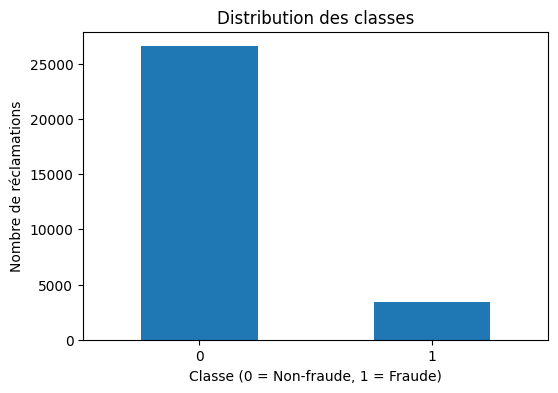

In [10]:
print("Nombre de réclamations par classe :")
print(df["fraud_label"].value_counts())

print("\nPourcentage par classe :")
print(df["fraud_label"].value_counts(normalize=True) * 100)


df["fraud_label"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribution des classes")
plt.xlabel("Classe (0 = Non-fraude, 1 = Fraude)")
plt.ylabel("Nombre de réclamations")
plt.xticks(rotation=0)
plt.show()



Statistiques de longueur des textes :
count    30000.000000
mean       447.782733
std          8.791862
min        419.000000
25%        441.000000
50%        448.000000
75%        454.000000
max        474.000000
Name: text_length, dtype: float64


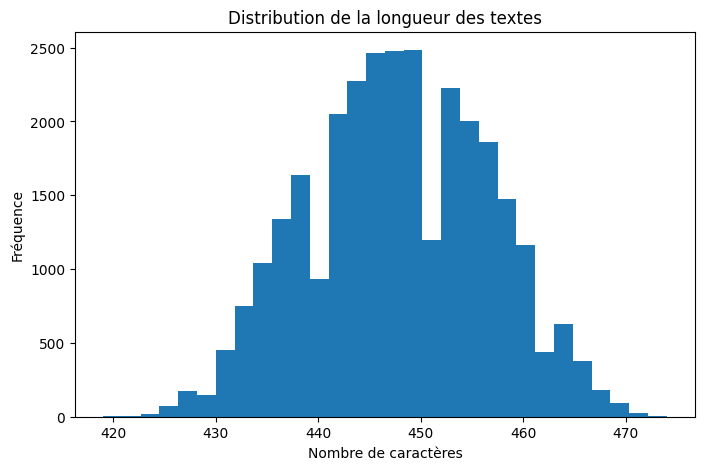

In [11]:
df["text_length"] = df["claim_text_enriched"].astype(str).str.len()

print("Statistiques de longueur des textes :")
print(df["text_length"].describe())


plt.figure(figsize=(8, 5))

plt.hist(df["text_length"], bins=30)

plt.title("Distribution de la longueur des textes")
plt.xlabel("Nombre de caractères")
plt.ylabel("Fréquence")

plt.show()

In [12]:
# Supprimer les valeurs manquantes dans les colonnes nécessaires
df = df.dropna(
    subset=["claim_text_enriched", "fraud_label"]
).copy()

# Supprimer les textes vides ou composés uniquement d'espaces
df = df[
    df["claim_text_enriched"].astype(str).str.strip() != ""
].copy()

# Supprimer les doublons exacts (texte et label identiques)
df = df.drop_duplicates(
    subset=["claim_text_enriched", "fraud_label"]
).copy()

# Vérifier les labels
print("Labels présents :", sorted(df["fraud_label"].unique()))

print("\nDimensions après nettoyage :", df.shape)

print("\nValeurs manquantes restantes :")
print(df[["claim_text_enriched", "fraud_label"]].isnull().sum())

print("\nDoublons restants :")
print(df.duplicated(
    subset=["claim_text_enriched", "fraud_label"]
).sum())

Labels présents : [np.int64(0), np.int64(1)]

Dimensions après nettoyage : (30000, 3)

Valeurs manquantes restantes :
claim_text_enriched    0
fraud_label            0
dtype: int64

Doublons restants :
0


In [13]:
# Séparer les textes et les labels
X = df["claim_text_enriched"]
y = df["fraud_label"]

# Train 70% et temporaire 30%
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Validation 15% et Test 15%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Vérifier les dimensions
print("Train      :", len(X_train))
print("Validation :", len(X_val))
print("Test       :", len(X_test))

Train      : 21000
Validation : 4500
Test       : 4500


In [14]:
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print(labels.value_counts(normalize=True) * 100)


Train:
fraud_label
0    88.533333
1    11.466667
Name: proportion, dtype: float64

Validation:
fraud_label
0    88.533333
1    11.466667
Name: proportion, dtype: float64

Test:
fraud_label
0    88.533333
1    11.466667
Name: proportion, dtype: float64


In [15]:
train_df = pd.DataFrame({
    "claim_text_enriched": X_train,
    "fraud_label": y_train
})

val_df = pd.DataFrame({
    "claim_text_enriched": X_val,
    "fraud_label": y_val
})

test_df = pd.DataFrame({
    "claim_text_enriched": X_test,
    "fraud_label": y_test
})

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("Les trois fichiers ont été sauvegardés !")

Les trois fichiers ont été sauvegardés !


In [38]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import average_precision_score, f1_score
from sklearn.metrics import precision_score, recall_score
import numpy as np

# ==================================================
# OPTIMISATION TF-IDF + MULTINOMIAL NAIVE BAYES
# ==================================================

best_auc = 0
best_params = None
best_model = None
best_vectorizer = None

alphas = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]

ngram_options = [(1, 1), (1, 2)]
min_df_options = [2, 3, 5]
max_features_options = [10000, 20000, None]

for ngram in ngram_options:
    for min_df in min_df_options:
        for max_features in max_features_options:

            vectorizer = TfidfVectorizer(
                ngram_range=ngram,
                min_df=min_df,
                max_features=max_features,
                sublinear_tf=True
            )

            # TF-IDF apprend uniquement sur Train
            X_train_tfidf = vectorizer.fit_transform(X_train)
            X_val_tfidf = vectorizer.transform(X_val)

            for alpha in alphas:

                model = MultinomialNB(alpha=alpha)
                model.fit(X_train_tfidf, y_train)

                val_probs = model.predict_proba(
                    X_val_tfidf
                )[:, 1]

                val_auc = average_precision_score(
                    y_val, val_probs
                )

                print(
                    f"ngram={ngram}, min_df={min_df}, "
                    f"max_features={max_features}, "
                    f"alpha={alpha}, AUC-PR={val_auc:.4f}"
                )

                if val_auc > best_auc:
                    best_auc = val_auc
                    best_params = {
                        "ngram_range": ngram,
                        "min_df": min_df,
                        "max_features": max_features,
                        "alpha": alpha
                    }
                    best_model = model
                    best_vectorizer = vectorizer

print("\n===== MEILLEURE CONFIGURATION =====")
print("Paramètres :", best_params)
print("AUC-PR Validation :", round(best_auc, 4))


ngram=(1, 1), min_df=2, max_features=10000, alpha=0.01, AUC-PR=0.1323
ngram=(1, 1), min_df=2, max_features=10000, alpha=0.05, AUC-PR=0.1319
ngram=(1, 1), min_df=2, max_features=10000, alpha=0.1, AUC-PR=0.1330
ngram=(1, 1), min_df=2, max_features=10000, alpha=0.2, AUC-PR=0.1327
ngram=(1, 1), min_df=2, max_features=10000, alpha=0.5, AUC-PR=0.1244
ngram=(1, 1), min_df=2, max_features=10000, alpha=1.0, AUC-PR=0.1237
ngram=(1, 1), min_df=2, max_features=10000, alpha=2.0, AUC-PR=0.1233
ngram=(1, 1), min_df=2, max_features=20000, alpha=0.01, AUC-PR=0.1301
ngram=(1, 1), min_df=2, max_features=20000, alpha=0.05, AUC-PR=0.1290
ngram=(1, 1), min_df=2, max_features=20000, alpha=0.1, AUC-PR=0.1311
ngram=(1, 1), min_df=2, max_features=20000, alpha=0.2, AUC-PR=0.1309
ngram=(1, 1), min_df=2, max_features=20000, alpha=0.5, AUC-PR=0.1243
ngram=(1, 1), min_df=2, max_features=20000, alpha=1.0, AUC-PR=0.1226
ngram=(1, 1), min_df=2, max_features=20000, alpha=2.0, AUC-PR=0.1229
ngram=(1, 1), min_df=2, max_fe

In [39]:

# Probabilités sur Validation avec le meilleur modèle
X_val_best = best_vectorizer.transform(X_val)

val_probs = best_model.predict_proba(X_val_best)[:, 1]

best_f1 = 0
best_threshold = 0

for threshold in np.arange(0.01, 0.51, 0.01):

    predictions = (val_probs >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    print(
        f"Seuil={threshold:.2f} | "
        f"Precision={precision:.4f} | "
        f"Recall={recall:.4f} | "
        f"F1={f1:.4f}"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("\nMeilleur seuil :", best_threshold)
print("Meilleur F1 Validation :", best_f1)


Seuil=0.01 | Precision=0.1145 | Recall=0.9981 | F1=0.2054
Seuil=0.02 | Precision=0.1146 | Recall=0.9961 | F1=0.2056
Seuil=0.03 | Precision=0.1155 | Recall=0.9942 | F1=0.2069
Seuil=0.04 | Precision=0.1157 | Recall=0.9864 | F1=0.2071
Seuil=0.05 | Precision=0.1157 | Recall=0.9806 | F1=0.2070
Seuil=0.06 | Precision=0.1164 | Recall=0.9729 | F1=0.2079
Seuil=0.07 | Precision=0.1202 | Recall=0.9477 | F1=0.2133
Seuil=0.08 | Precision=0.1263 | Recall=0.8682 | F1=0.2206
Seuil=0.09 | Precision=0.1390 | Recall=0.7752 | F1=0.2358
Seuil=0.10 | Precision=0.1580 | Recall=0.6957 | F1=0.2575
Seuil=0.11 | Precision=0.1735 | Recall=0.5988 | F1=0.2690
Seuil=0.12 | Precision=0.1886 | Recall=0.5116 | F1=0.2756
Seuil=0.13 | Precision=0.2091 | Recall=0.4205 | F1=0.2793
Seuil=0.14 | Precision=0.2287 | Recall=0.3333 | F1=0.2713
Seuil=0.15 | Precision=0.2500 | Recall=0.2597 | F1=0.2548
Seuil=0.16 | Precision=0.2519 | Recall=0.1919 | F1=0.2178
Seuil=0.17 | Precision=0.2727 | Recall=0.1453 | F1=0.1896
Seuil=0.18 | P

In [40]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Transformation du Test avec le TF-IDF déjà entraîné
X_test_best = best_vectorizer.transform(X_test)

# Probabilités de fraude
test_probs = best_model.predict_proba(X_test_best)[:, 1]

# Utilisation du seuil choisi sur Validation
test_predictions = (
    test_probs >= best_threshold
).astype(int)

print("===== NAIVE BAYES TF-IDF OPTIMISÉ - TEST FINAL =====")
print("Paramètres :", best_params)
print("Seuil :", best_threshold)

print("\nAUC-PR Test :",
      round(average_precision_score(y_test, test_probs), 4))

print("\nRapport de classification :")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Non-fraude (0)", "Fraude (1)"],
    digits=4
))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, test_predictions))


===== NAIVE BAYES TF-IDF OPTIMISÉ - TEST FINAL =====
Paramètres : {'ngram_range': (1, 2), 'min_df': 5, 'max_features': 10000, 'alpha': 0.01}
Seuil : 0.13

AUC-PR Test : 0.1956

Rapport de classification :
                precision    recall  f1-score   support

Non-fraude (0)     0.9131    0.7836    0.8434      3984
    Fraude (1)     0.2026    0.4244    0.2743       516

      accuracy                         0.7424      4500
     macro avg     0.5579    0.6040    0.5589      4500
  weighted avg     0.8317    0.7424    0.7782      4500


Matrice de confusion :
[[3122  862]
 [ 297  219]]


In [ ]:
# Partie avec qui travailler

=== Dimensions des matrices TF-IDF ===
Train      : (21000, 20000)
Validation : (4500, 20000)
Test       : (4500, 20000)

Taille du vocabulaire : 20000
✅ 'no'
❌ 'not'
✅ 'no police'
✅ 'police report'
✅ 'no witnesses'

Densité train : 0.5964%
Valeurs non nulles : 2,504,928


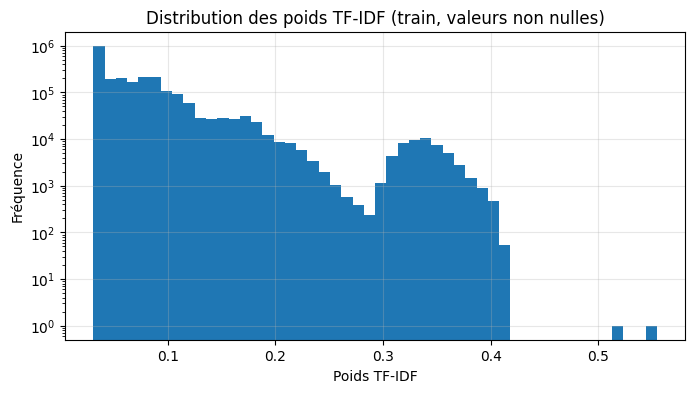

In [16]:
# ============================================================
# Partie 6 — Transformation TF-IDF (version recommandée)
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
    # pas de stop_words : on GARDE "no", "not", "none" (signaux de fraude)
)

# Fit UNIQUEMENT sur le train
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

# Vérifications
print("=== Dimensions des matrices TF-IDF ===")
print(f"Train      : {X_train_tfidf.shape}")
print(f"Validation : {X_val_tfidf.shape}")
print(f"Test       : {X_test_tfidf.shape}")
print(f"\nTaille du vocabulaire : {len(tfidf.vocabulary_)}")

# Vérifier que "no police" est bien capturé
for term in ["no", "not", "no police", "police report", "no witnesses"]:
    status = "✅" if term in tfidf.vocabulary_ else "❌"
    print(f"{status} '{term}'")

# Densité et valeurs non nulles
density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f"\nDensité train : {density:.4%}")
print(f"Valeurs non nulles : {X_train_tfidf.nnz:,}")

# Distribution des poids TF-IDF
plt.figure(figsize=(8, 4))
plt.hist(X_train_tfidf.data, bins=50)
plt.title("Distribution des poids TF-IDF (train, valeurs non nulles)")
plt.xlabel("Poids TF-IDF")
plt.ylabel("Fréquence")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
# ============================================================
# Partie 7 — Entraînement Naive Bayes avec TF-IDF
# ============================================================

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

import pandas as pd

# ============================================================
# 1. TESTER PLUSIEURS VALEURS DE ALPHA
# ============================================================

alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

results_nb = []

best_alpha = None
best_ap = -1
best_nb_model = None

for alpha in alpha_values:

    model = MultinomialNB(alpha=alpha)

    model.fit(X_train_tfidf, y_train)

    y_val_proba = model.predict_proba(X_val_tfidf)[:, 1]

    ap = average_precision_score(y_val, y_val_proba)

    results_nb.append({
        "Alpha": alpha,
        "AUC-PR": ap
    })

    print(f"Alpha = {alpha} | AUC-PR = {ap:.4f}")

    if ap > best_ap:
        best_ap = ap
        best_alpha = alpha
        best_nb_model = model

results_nb_df = pd.DataFrame(results_nb)

display(results_nb_df)

print("Meilleur alpha :", best_alpha)
print("Meilleure AUC-PR :", round(best_ap, 4))


# ============================================================
# 2. RECHERCHE DU MEILLEUR SEUIL
# ============================================================

y_val_proba_best = best_nb_model.predict_proba(X_val_tfidf)[:, 1]

thresholds = [
    0.01, 0.02, 0.05, 0.10, 0.15,
    0.20, 0.25, 0.30, 0.40, 0.50
]

threshold_results = []

for threshold in thresholds:

    y_pred = (y_val_proba_best >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_val, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

best_threshold = threshold_df.loc[
    threshold_df["F1-score"].idxmax(),
    "Threshold"
]

print("Meilleur seuil :", best_threshold)


# ============================================================
# 3. ÉVALUATION SUR VALIDATION
# ============================================================

y_val_pred_best = (
    y_val_proba_best >= best_threshold
).astype(int)

print("\n=== NAIVE BAYES TF-IDF OPTIMISÉ ===")

print("Alpha :", best_alpha)
print("Seuil :", best_threshold)
print("AUC-PR :", round(best_ap, 4))

print(classification_report(
    y_val,
    y_val_pred_best,
    target_names=["Non-fraude (0)", "Fraude (1)"],
    digits=4,
    zero_division=0
))

Alpha = 0.01 | AUC-PR = 0.1437
Alpha = 0.1 | AUC-PR = 0.1521
Alpha = 0.5 | AUC-PR = 0.1361
Alpha = 1.0 | AUC-PR = 0.1292
Alpha = 2.0 | AUC-PR = 0.1242
Alpha = 5.0 | AUC-PR = 0.1201


,Alpha,AUC-PR
0,0.01,0.143685
1,0.10,0.152139
2,0.50,0.136061
3,1.00,0.129248
4,2.00,0.124171
5,5.00,0.120070


Meilleur alpha : 0.1
Meilleure AUC-PR : 0.1521


,Threshold,Precision,Recall,F1-score,Accuracy
0,0.01,0.114667,1.000000,0.205742,0.114667
1,0.02,0.114667,1.000000,0.205742,0.114667
2,0.05,0.139236,0.777132,0.236160,0.423556
3,0.10,0.147097,0.220930,0.176607,0.763778
4,0.15,0.163142,0.104651,0.127509,0.835778
5,0.20,0.147651,0.042636,0.066165,0.862000
6,0.25,0.142857,0.019380,0.034130,0.874222
7,0.30,0.171429,0.011628,0.021779,0.880222
8,0.40,0.181818,0.003876,0.007590,0.883778
9,0.50,0.200000,0.001938,0.003839,0.884667


Meilleur seuil : 0.05

=== NAIVE BAYES TF-IDF OPTIMISÉ ===
Alpha : 0.1
Seuil : 0.05
AUC-PR : 0.1521
                precision    recall  f1-score   support

Non-fraude (0)     0.9290    0.3778    0.5371      3984
    Fraude (1)     0.1392    0.7771    0.2362       516

      accuracy                         0.4236      4500
     macro avg     0.5341    0.5774    0.3866      4500
  weighted avg     0.8385    0.4236    0.5026      4500



In [29]:
# ============================================================
# Partie 8 — Évaluation finale Naive Bayes sur Test
# ============================================================

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix
)

# Probabilités sur Test
y_test_proba_nb = best_nb_model.predict_proba(
    X_test_tfidf
)[:, 1]

# Prédictions avec le seuil choisi sur Validation
y_test_pred_nb = (
    y_test_proba_nb >= best_threshold
).astype(int)

print("===== NAIVE BAYES TF-IDF - TEST FINAL =====")

print(classification_report(
    y_test,
    y_test_pred_nb,
    target_names=["Non-fraude (0)", "Fraude (1)"],
    digits=4,
    zero_division=0
))

print("AUC-PR Test :",
      round(average_precision_score(
          y_test, y_test_proba_nb
      ), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_test_pred_nb))

===== NAIVE BAYES TF-IDF - TEST FINAL =====
                precision    recall  f1-score   support

Non-fraude (0)     0.9351    0.3722    0.5325      3984
    Fraude (1)     0.1417    0.8004    0.2408       516

      accuracy                         0.4213      4500
     macro avg     0.5384    0.5863    0.3867      4500
  weighted avg     0.8441    0.4213    0.4990      4500

AUC-PR Test : 0.1514

Matrice de confusion :
[[1483 2501]
 [ 103  413]]


In [56]:

# ============================================================
# CORRECTION : RECONSTRUIRE LES MATRICES TF-IDF
# ============================================================

# Vérifier le vocabulaire du vectorizer d'entraînement
print("Taille du vocabulaire TF-IDF :", len(tfidf.vocabulary_))
print("Caractéristiques attendues par NB :", best_nb_model.n_features_in_)

# Reconstruire les matrices avec le bon vectorizer
X_test_tfidf = tfidf.transform(X_test)
X_val_tfidf = tfidf.transform(X_val)

# Vérifier les dimensions
print("\nNouvelle dimension Test :", X_test_tfidf.shape)
print("Nouvelle dimension Validation :", X_val_tfidf.shape)

# Vérifier la compatibilité
assert X_test_tfidf.shape[1] == best_nb_model.n_features_in_
assert X_val_tfidf.shape[1] == best_nb_model.n_features_in_

# Calculer les probabilités
y_test_proba_nb = best_nb_model.predict_proba(X_test_tfidf)[:, 1]
val_probabilities_nb = best_nb_model.predict_proba(X_val_tfidf)[:, 1]

# Prédictions
y_test_pred_nb = (
    y_test_proba_nb >= best_threshold
).astype(int)

print("\n✅ Correction réussie !")
print("Nombre de probabilités Test :", len(y_test_proba_nb))


Taille du vocabulaire TF-IDF : 20000
Caractéristiques attendues par NB : 20000

Nouvelle dimension Test : (4500, 20000)
Nouvelle dimension Validation : (4500, 20000)

✅ Correction réussie !
Nombre de probabilités Test : 4500


Modèle : MultinomialNB(alpha=0.1)
Meilleur alpha : 0.1
Meilleur seuil : 0.13
Nombre de données Test : 4500


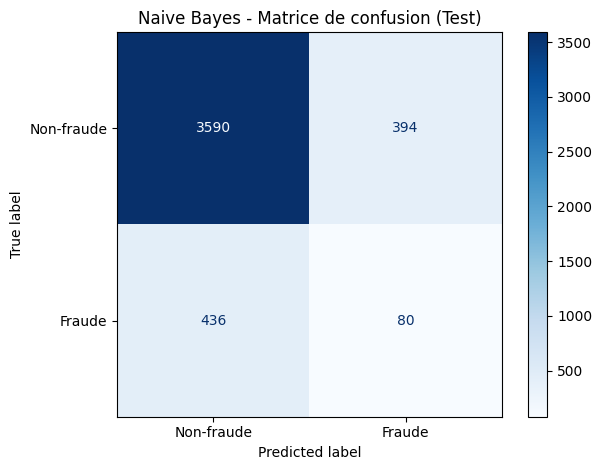

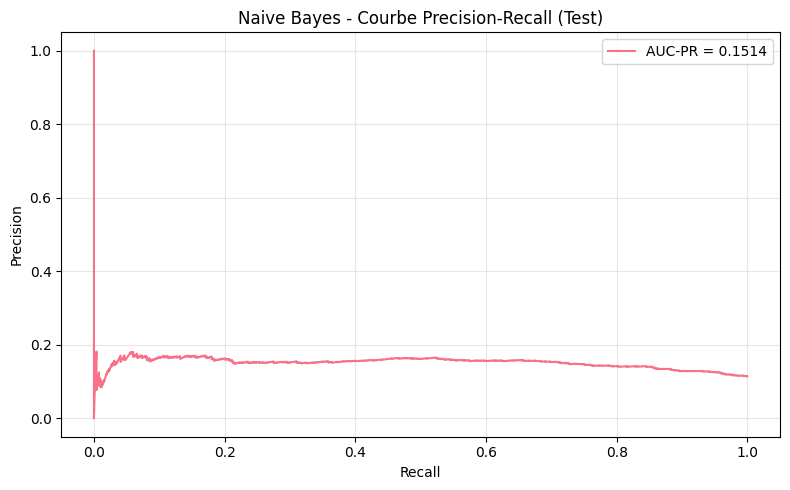

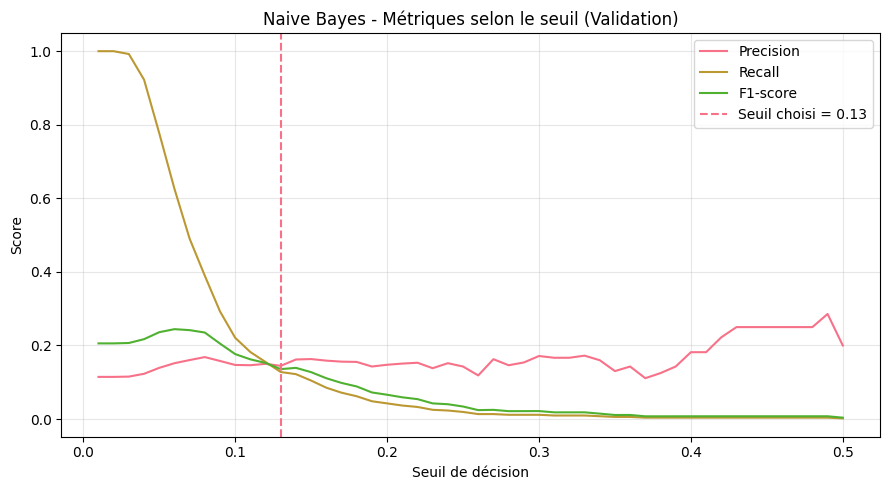

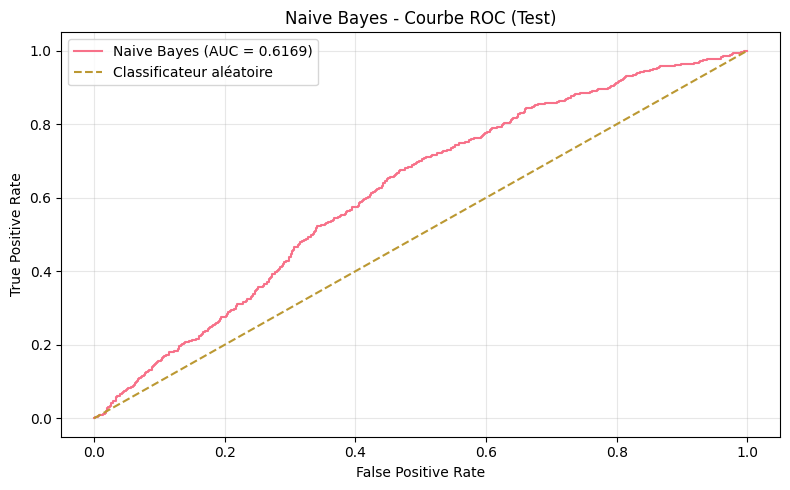

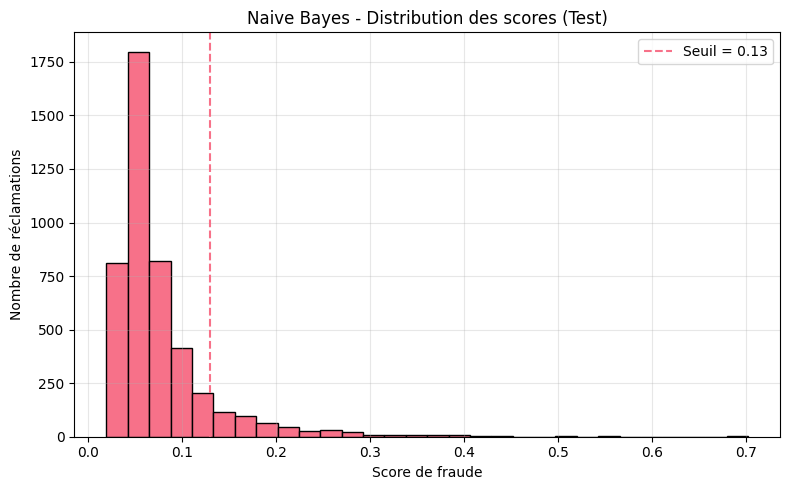

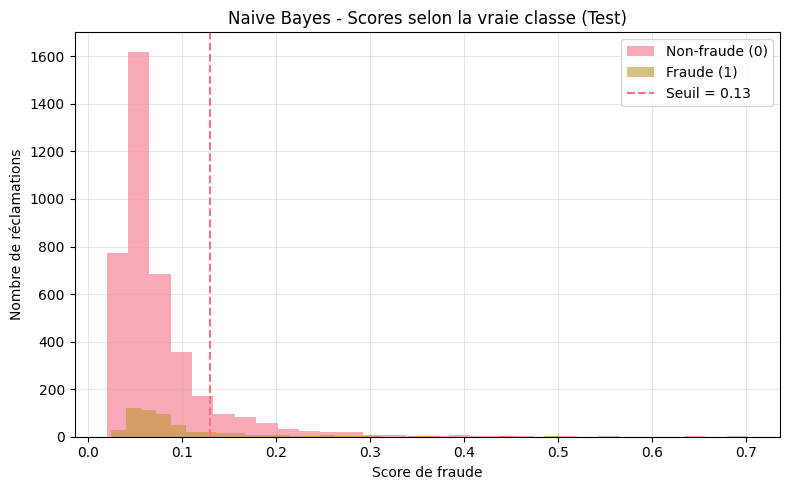

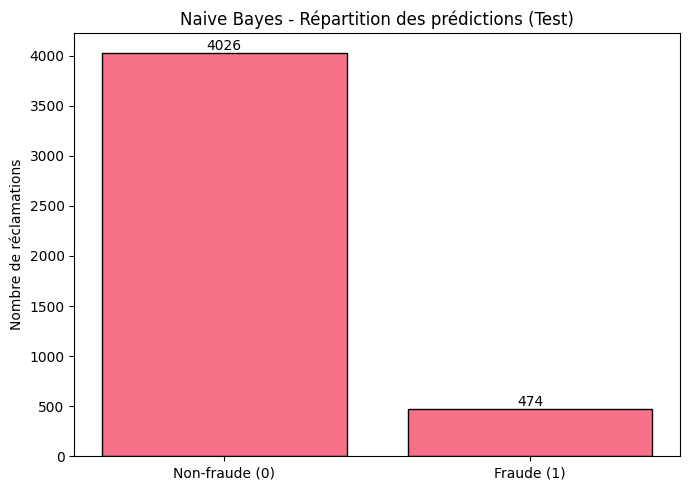


 RESULTATS FINAUX - NAIVE BAYES TF-IDF
Alpha : 0.1
Seuil : 0.13
Accuracy : 0.8156
Precision fraude : 0.1688
Recall fraude : 0.155
F1-score fraude : 0.1616
AUC-PR : 0.1514
AUC-ROC : 0.6169

Matrice de confusion :
[[3590  394]
 [ 436   80]]


In [57]:

# ============================================================
# PARTIE 8 — VISUALISATION DES RESULTATS NAIVE BAYES TF-IDF
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. PREPARATION DES DONNEES
# ============================================================

# Utiliser le meilleur modèle obtenu dans la Partie 7
model_nb = best_nb_model

# Probabilités de fraude sur Test et Validation
y_test_proba_nb = model_nb.predict_proba(X_test_tfidf)[:, 1]
val_probabilities_nb = model_nb.predict_proba(X_val_tfidf)[:, 1]

# Vraies étiquettes
y_test_true_nb = np.asarray(y_test)
y_val_true_nb = np.asarray(y_val)

# Seuil sélectionné sur Validation
best_threshold_nb = best_threshold

# Prédictions finales sur Test
y_test_pred_nb = (
    y_test_proba_nb >= best_threshold_nb
).astype(int)

print("Modèle :", model_nb)
print("Meilleur alpha :", best_alpha)
print("Meilleur seuil :", best_threshold_nb)
print("Nombre de données Test :", len(y_test_true_nb))


# ============================================================
# GRAPHIQUE 1 — MATRICE DE CONFUSION
# ============================================================

cm = confusion_matrix(y_test_true_nb, y_test_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-fraude", "Fraude"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes - Matrice de confusion (Test)")
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 2 — COURBE PRECISION-RECALL
# ============================================================

precision, recall, thresholds_pr = precision_recall_curve(
    y_test_true_nb,
    y_test_proba_nb
)

ap_test = average_precision_score(
    y_test_true_nb,
    y_test_proba_nb
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AUC-PR = {ap_test:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Naive Bayes - Courbe Precision-Recall (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 3 — METRIQUES SELON LE SEUIL
# IMPORTANT : utilisation de VALIDATION
# ============================================================

thresholds_to_plot = np.linspace(0.01, 0.50, 50)

precisions = []
recalls = []
f1_scores = []

for threshold in thresholds_to_plot:

    predictions = (
        val_probabilities_nb >= threshold
    ).astype(int)

    precisions.append(
        precision_score(y_val_true_nb, predictions, zero_division=0)
    )

    recalls.append(
        recall_score(y_val_true_nb, predictions, zero_division=0)
    )

    f1_scores.append(
        f1_score(y_val_true_nb, predictions, zero_division=0)
    )

plt.figure(figsize=(9, 5))

plt.plot(thresholds_to_plot, precisions, label="Precision")
plt.plot(thresholds_to_plot, recalls, label="Recall")
plt.plot(thresholds_to_plot, f1_scores, label="F1-score")

plt.axvline(
    best_threshold_nb,
    linestyle="--",
    label=f"Seuil choisi = {best_threshold_nb:.2f}"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Naive Bayes - Métriques selon le seuil (Validation)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 4 — COURBE ROC
# ============================================================

fpr, tpr, thresholds_roc = roc_curve(
    y_test_true_nb,
    y_test_proba_nb
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Naive Bayes (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Classificateur aléatoire")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Naive Bayes - Courbe ROC (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 5 — DISTRIBUTION DES SCORES DE FRAUDE
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    y_test_proba_nb,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    best_threshold_nb,
    linestyle="--",
    label=f"Seuil = {best_threshold_nb:.2f}"
)

plt.xlabel("Score de fraude")
plt.ylabel("Nombre de réclamations")
plt.title("Naive Bayes - Distribution des scores (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 6 — SCORES SELON LA VRAIE CLASSE
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    y_test_proba_nb[y_test_true_nb == 0],
    bins=30,
    alpha=0.6,
    label="Non-fraude (0)"
)

plt.hist(
    y_test_proba_nb[y_test_true_nb == 1],
    bins=30,
    alpha=0.6,
    label="Fraude (1)"
)

plt.axvline(
    best_threshold_nb,
    linestyle="--",
    label=f"Seuil = {best_threshold_nb:.2f}"
)

plt.xlabel("Score de fraude")
plt.ylabel("Nombre de réclamations")
plt.title("Naive Bayes - Scores selon la vraie classe (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 7 — REPARTITION DES PREDICTIONS
# ============================================================

classes, counts = np.unique(
    y_test_pred_nb,
    return_counts=True
)

labels = ["Non-fraude (0)", "Fraude (1)"]

count_nonfraud = np.sum(y_test_pred_nb == 0)
count_fraud = np.sum(y_test_pred_nb == 1)

plt.figure(figsize=(7, 5))

plt.bar(
    labels,
    [count_nonfraud, count_fraud],
    edgecolor="black"
)

plt.ylabel("Nombre de réclamations")
plt.title("Naive Bayes - Répartition des prédictions (Test)")

for i, value in enumerate([count_nonfraud, count_fraud]):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()


# ============================================================
# RESULTATS FINAUX SUR TEST
# ============================================================

print("\n========================================")
print(" RESULTATS FINAUX - NAIVE BAYES TF-IDF")
print("========================================")

print("Alpha :", best_alpha)
print("Seuil :", best_threshold_nb)
print("Accuracy :", round(np.mean(y_test_pred_nb == y_test_true_nb), 4))

print("Precision fraude :",
      round(precision_score(y_test_true_nb, y_test_pred_nb, zero_division=0), 4))

print("Recall fraude :",
      round(recall_score(y_test_true_nb, y_test_pred_nb, zero_division=0), 4))

print("F1-score fraude :",
      round(f1_score(y_test_true_nb, y_test_pred_nb, zero_division=0), 4))

print("AUC-PR :", round(ap_test, 4))
print("AUC-ROC :", round(roc_auc, 4))

print("\nMatrice de confusion :")
print(cm)


In [30]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Appareil utilisé :", device)

Appareil utilisé : cuda


In [31]:
!pip install -q transformers

In [47]:

# ============================================================
# PARTIE : DISTILBERT - ANALYSE TEXTUELLE DES FRAUDES
# ============================================================

!pip install -q transformers datasets accelerate

import torch
import pandas as pd
import numpy as np

from datasets import Dataset
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments
)

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# ============================================================
# 1. VERIFIER LE MATERIEL
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# ============================================================
# 2. PREPARATION DES TROIS DATASETS
# ============================================================

train_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "text": X_train.tolist(),
        "label": y_train.tolist()
    })
)

val_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "text": X_val.tolist(),
        "label": y_val.tolist()
    })
)

test_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "text": X_test.tolist(),
        "label": y_test.tolist()
    })
)

print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

# ============================================================
# 3. TOKENISATION
# ============================================================

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

columns = ["input_ids", "attention_mask", "label"]

train_dataset.set_format(type="torch", columns=columns)
val_dataset.set_format(type="torch", columns=columns)
test_dataset.set_format(type="torch", columns=columns)

print("Tokenisation terminée.")

# ============================================================
# 4. CHARGEMENT DE DISTILBERT
# ============================================================

model_bert = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# ============================================================
# 5. PARAMETRES D'ENTRAINEMENT
# ============================================================

training_args = TrainingArguments(
    output_dir="./distilbert_results",

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    fp16=torch.cuda.is_available(),

    logging_steps=100,
    report_to="none"
)

# ============================================================
# 6. ENTRAINEMENT SUR TRAIN ET VALIDATION
# ============================================================

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

print("\nDébut de l'entraînement DistilBERT...")

trainer.train()

print("\nEntraînement terminé.")
print("Meilleur modèle chargé automatiquement.")

# ============================================================
# 7. EVALUATION SUR VALIDATION
# ============================================================

val_output = trainer.predict(val_dataset)

val_logits = val_output.predictions

val_probabilities = torch.softmax(
    torch.tensor(val_logits),
    dim=1
).numpy()[:, 1]

y_val_true = np.array(y_val)

print("\nAUC-PR Validation :",
      round(average_precision_score(y_val_true, val_probabilities), 4))

# ============================================================
# 8. RECHERCHE DU MEILLEUR SEUIL SUR VALIDATION
# CRITERE : MEILLEUR F1-SCORE
# ============================================================

thresholds = np.arange(0.05, 0.96, 0.05)

best_threshold_bert = 0.5
best_f1_bert = 0

print("\n===== RECHERCHE DU SEUIL =====")

for threshold in thresholds:

    y_val_pred = (val_probabilities >= threshold).astype(int)

    current_f1 = f1_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    )

    print(
        f"Seuil : {threshold:.2f} | "
        f"F1 fraude : {current_f1:.4f}"
    )

    if current_f1 > best_f1_bert:
        best_f1_bert = current_f1
        best_threshold_bert = threshold

print("\nMeilleur seuil :", best_threshold_bert)
print("Meilleur F1 Validation :", round(best_f1_bert, 4))

# ============================================================
# 9. EVALUATION FINALE SUR TEST
# ============================================================

test_output = trainer.predict(test_dataset)

test_logits = test_output.predictions

y_test_proba_bert = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()[:, 1]

y_test_pred_bert = (
    y_test_proba_bert >= best_threshold_bert
).astype(int)

print("\n===== RESULTATS DISTILBERT SUR TEST =====")

print(
    classification_report(
        y_test,
        y_test_pred_bert,
        target_names=["Non-fraude", "Fraude"],
        digits=4,
        zero_division=0
    )
)

print("Accuracy :",
      round(accuracy_score(y_test, y_test_pred_bert), 4))

print("Precision fraude :",
      round(precision_score(y_test, y_test_pred_bert, zero_division=0), 4))

print("Recall fraude :",
      round(recall_score(y_test, y_test_pred_bert, zero_division=0), 4))

print("F1 fraude :",
      round(f1_score(y_test, y_test_pred_bert, zero_division=0), 4))

print("AUC-PR Test :",
      round(average_precision_score(y_test, y_test_proba_bert), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_test_pred_bert))

# ============================================================
# 10. SCORE DE SUSPICION POUR LE DECISION AGENT
# ============================================================

results_text_agent = pd.DataFrame({
    "claim_text": X_test.reset_index(drop=True),
    "fraud_score": y_test_proba_bert,
    "fraud_prediction": y_test_pred_bert
})

results_text_agent.to_csv(
    "distilbert_text_agent_results.csv",
    index=False
)

print("Résultats du Text Agent sauvegardés.")

# ============================================================
# 11. SAUVEGARDE DU MODELE
# ============================================================

trainer.save_model("./distilbert_insurance_frauddd")
tokenizer.save_pretrained("./distilbert_insurance_frauddd")

print("\nModèle et tokenizer sauvegardés.")


Appareil utilisé : cuda
Train : 21000
Validation : 4500
Test : 4500


Map:   0%|          | 0/21000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Tokenisation terminée.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (7 outputs left out)


AUC-PR Validation : 0.2406

===== RECHERCHE DU SEUIL =====
Seuil : 0.05 | F1 fraude : 0.2057
Seuil : 0.10 | F1 fraude : 0.3380
Seuil : 0.15 | F1 fraude : 0.3380
Seuil : 0.20 | F1 fraude : 0.3380
Seuil : 0.25 | F1 fraude : 0.2320
Seuil : 0.30 | F1 fraude : 0.2320
Seuil : 0.35 | F1 fraude : 0.2070
Seuil : 0.40 | F1 fraude : 0.1694
Seuil : 0.45 | F1 fraude : 0.0505
Seuil : 0.50 | F1 fraude : 0.0000
Seuil : 0.55 | F1 fraude : 0.0000
Seuil : 0.60 | F1 fraude : 0.0000
Seuil : 0.65 | F1 fraude : 0.0000
Seuil : 0.70 | F1 fraude : 0.0000
Seuil : 0.75 | F1 fraude : 0.0000
Seuil : 0.80 | F1 fraude : 0.0000
Seuil : 0.85 | F1 fraude : 0.0000
Seuil : 0.90 | F1 fraude : 0.0000
Seuil : 0.95 | F1 fraude : 0.0000

Meilleur seuil : 0.1
Meilleur F1 Validation : 0.338



===== RESULTATS DISTILBERT SUR TEST =====
              precision    recall  f1-score   support

  Non-fraude     0.9432    0.7425    0.8309      3984
      Fraude     0.2478    0.6550    0.3596       516

    accuracy                         0.7324      4500
   macro avg     0.5955    0.6988    0.5952      4500
weighted avg     0.8635    0.7324    0.7769      4500

Accuracy : 0.7324
Precision fraude : 0.2478
Recall fraude : 0.655
F1 fraude : 0.3596
AUC-PR Test : 0.2745

Matrice de confusion :
[[2958 1026]
 [ 178  338]]
Résultats du Text Agent sauvegardés.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modèle et tokenizer sauvegardés.


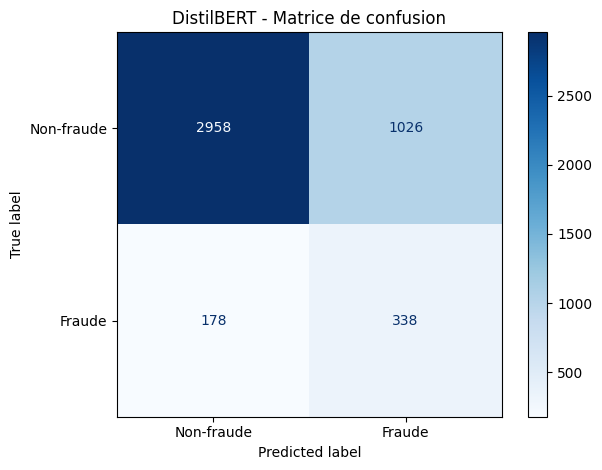

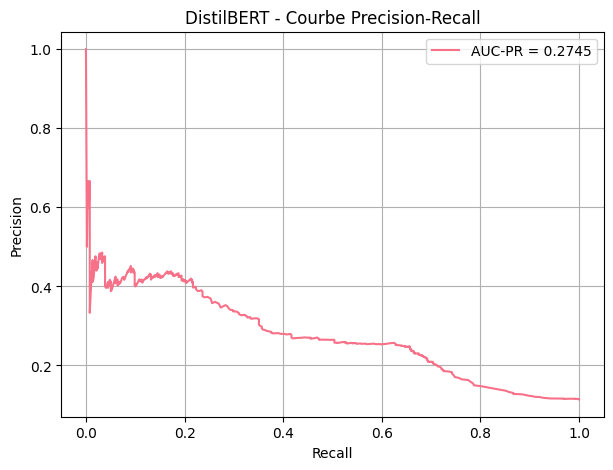

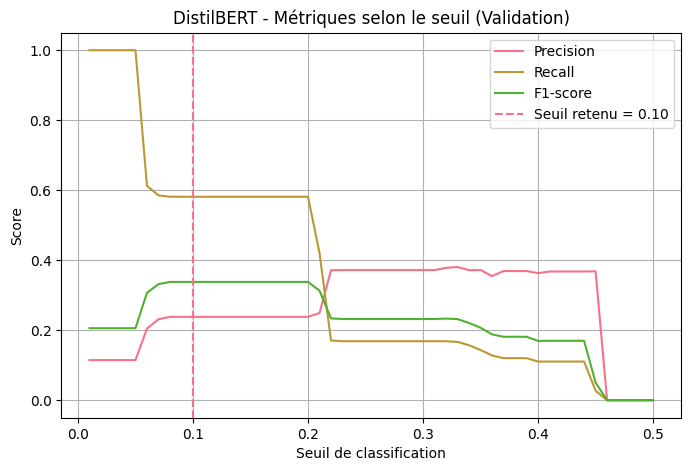

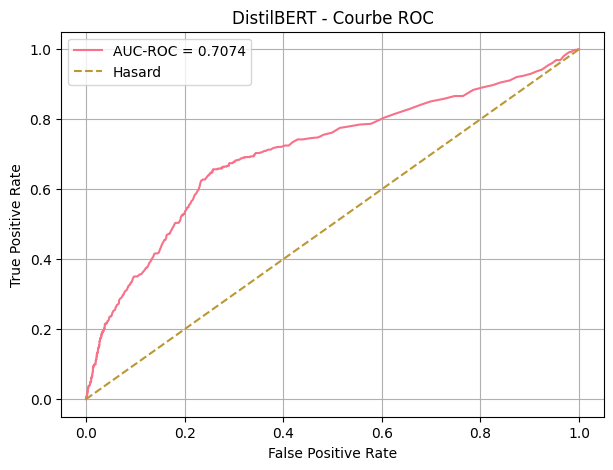

In [50]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

# ============================================================
# GRAPHIQUE 1 : MATRICE DE CONFUSION
# ============================================================

cm = confusion_matrix(y_test, y_test_pred_bert)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-fraude", "Fraude"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - Matrice de confusion")
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 2 : COURBE PRECISION-RECALL
# ============================================================

precision, recall, thresholds_pr = precision_recall_curve(
    y_test,
    y_test_proba_bert
)

auc_pr = average_precision_score(
    y_test,
    y_test_proba_bert
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"AUC-PR = {auc_pr:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DistilBERT - Courbe Precision-Recall")
plt.legend()
plt.grid()
plt.show()


# ============================================================
# GRAPHIQUE 3 : METRIQUES SELON LE SEUIL
# ============================================================

thresholds_graph = np.arange(0.01, 0.51, 0.01)

precisions = []
recalls = []
f1_scores = []

for threshold in thresholds_graph:

    predictions = (
        y_val_true * 0 +
        (val_probabilities >= threshold).astype(int)
    )

    precisions.append(
        precision_score(y_val_true, predictions, zero_division=0)
    )

    recalls.append(
        recall_score(y_val_true, predictions, zero_division=0)
    )

    f1_scores.append(
        f1_score(y_val_true, predictions, zero_division=0)
    )

plt.figure(figsize=(8, 5))
plt.plot(thresholds_graph, precisions, label="Precision")
plt.plot(thresholds_graph, recalls, label="Recall")
plt.plot(thresholds_graph, f1_scores, label="F1-score")

plt.axvline(
    best_threshold_bert,
    linestyle="--",
    label=f"Seuil retenu = {best_threshold_bert:.2f}"
)

plt.xlabel("Seuil de classification")
plt.ylabel("Score")
plt.title("DistilBERT - Métriques selon le seuil (Validation)")
plt.legend()
plt.grid()
plt.show()


# ============================================================
# GRAPHIQUE 4 : COURBE ROC
# ============================================================

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_test_proba_bert
)

auc_roc = roc_auc_score(
    y_test,
    y_test_proba_bert
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC-ROC = {auc_roc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Hasard")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DistilBERT - Courbe ROC")
plt.legend()
plt.grid()
plt.show()


In [33]:

# ============================================================
# COMPARAISON NAIVE BAYES VS DISTILBERT
# ============================================================

comparison = pd.DataFrame({
    "Modele": ["Naive Bayes", "DistilBERT"],
    "Accuracy": [0.4213, 0.7324],
    "Precision_Fraude": [0.1417, 0.2478],
    "Recall_Fraude": [0.8004, 0.6550],
    "F1_Fraude": [0.2408, 0.3596],
    "AUC_PR": [0.1514, 0.2755]
})

print("===== COMPARAISON FINALE SUR TEST =====")
display(comparison)


===== COMPARAISON FINALE SUR TEST =====


,Modele,Accuracy,Precision_Fraude,Recall_Fraude,F1_Fraude,AUC_PR
0,Naive Bayes,0.4213,0.1417,0.8004,0.2408,0.1514
1,DistilBERT,0.7324,0.2478,0.6550,0.3596,0.2755


In [48]:

import pandas as pd
from google.colab import files

# ============================================================
# EXPORT DES RESULTATS DU TEXT AGENT POUR LE DECISION AGENT
# ============================================================

df_pour_collegue = pd.DataFrame({
    "index_original": X_test.index,
    "score_distilbert": y_test_proba_bert,
    "vrai_label_fraude": y_test.values
})

# Sauvegarde CSV
df_pour_collegue.to_csv(
    "resultats_distilbert_pour_rf.csv",
    index=False
)

print("Fichier généré :", len(df_pour_collegue), "lignes")
print(df_pour_collegue.head())

# Téléchargement
files.download("resultats_distilbert_pour_rf.csv")


Fichier généré : 4500 lignes
   index_original  score_distilbert  vrai_label_fraude
0           25119          0.055772                  0
1           10945          0.055413                  0
2           17104          0.056081                  0
3            7630          0.056288                  1
4           13542          0.055566                  0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>